In [21]:
# Import the libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [22]:
# Dataset configuration

# Set seed for reproducibility
np.random.seed(100)

# Define number of routes
num_routes = 5000

# Generate route distance (between 10 and 300 km)
distance_km = np.random.randint(10, 301, size=num_routes)

# Generate an average speed between 35 and 90 km/h for each route
average_speed = np.random.uniform(35, 90, size=num_routes)

# Generate a random operational delay between 10 and 90 minutes
operational_delay = np.random.uniform(10, 90, size=num_routes)

# Calculate delivery time in minutes
delivery_time = (distance_km / average_speed) * 60 + operational_delay
delivery_time = np.round(delivery_time, 2)

# Generate a random number of stops for each route
num_of_stops = np.random.randint(1, 16, size=num_routes)

# Generate a random cost per kilometer for each route
cost_per_km = np.random.uniform(2.50, 5.00, size=num_routes)

# Generate a random cost per stop for each route
cost_per_stop = np.random.uniform(10, 30, size=num_routes)

# Calculate total route cost
route_cost = (
    distance_km * cost_per_km
    + num_of_stops * cost_per_stop
)
route_cost = np.round(route_cost, 2)

# Combine all variables into a single matrix (ndarray)
# Each row represents a route, and each column represents an operational metric
logistics_data = np.column_stack((
    distance_km,
    delivery_time,
    num_of_stops,
    route_cost
))

print("\nShape of our dataset:", logistics_data.shape)
print("Example of the first 5 routes (rows):")
print("\nColumns: [Distance (km), Delivery Time (min), Number of Stops, Route Cost (R$)]")
print(logistics_data[:5])
print("\nDataset created successfully.")


Shape of our dataset: (5000, 4)
Example of the first 5 routes (rows):

Columns: [Distance (km), Delivery Time (min), Number of Stops, Route Cost (R$)]
[[ 18.    60.69   4.   154.62]
 [290.   359.85  15.   971.29]
 [ 89.   106.29   1.   397.49]
 [ 63.    97.42  11.   408.5 ]
 [ 76.   123.5    5.   416.49]]

Dataset created successfully.


In [23]:
# Separate columns for easier analysis
distance_col = logistics_data[:,0]
delivery_time_col = logistics_data[:,1]
stops_col = logistics_data[:,2]
route_cost_col = logistics_data[:,3]

print("------- General Statistical Analysis ------")

# Mean
mean_distance = np.mean(distance_col)
mean_delivery_time = np.mean(delivery_time_col)
mean_stops = np.mean(stops_col)
mean_route_cost = np.mean(route_cost_col)

# Median
median_distance = np.median(distance_col)
median_delivery_time = np.median(delivery_time)
median_stops = np.median(stops_col)
median_route_cost = np.median(route_cost_col)

# Standard deviation
std_distance = np.std(distance_col)
std_delivery_time = np.std(delivery_time_col)
std_stops = np.std(stops_col)
std_route_cost = np.std(route_cost_col)

# Minimum and Maximum values
min_distance = np.min(distance_col)
max_distance = np.max(distance_col)

min_delivery_time = np.min(delivery_time_col)
max_delivery_time = np.max(delivery_time_col)

min_stops = np.min(stops_col)
max_stops = np.max(stops_col)

min_route_cost = np.min(route_cost_col)
max_route_cost = np.max(route_cost_col)

print(f"\nAverage Distance: {mean_distance:.2f} km")
print(f"Average Delivery Time: {mean_delivery_time:.2f} min")
print(f"Average Number of Stops: {mean_stops:.2f}")
print(f"Average Route Cost R$ {mean_route_cost:.2f}")

print(f"\nMedian Route Cost: R$ {median_route_cost:.2f}")
print(f"Route Cost Standard Deviation: R$ {std_route_cost:.2f}")
print(f"Minimum Route Cost: R$ {min_route_cost:.2f}")
print(f"Maximum Route Cost: R$ {max_route_cost:.2f}")

------- General Statistical Analysis ------

Average Distance: 155.44 km
Average Delivery Time: 210.17 min
Average Number of Stops: 7.99
Average Route Cost R$ 744.46

Median Route Cost: R$ 718.32
Route Cost Standard Deviation: R$ 355.52
Minimum Route Cost: R$ 58.19
Maximum Route Cost: R$ 1787.44


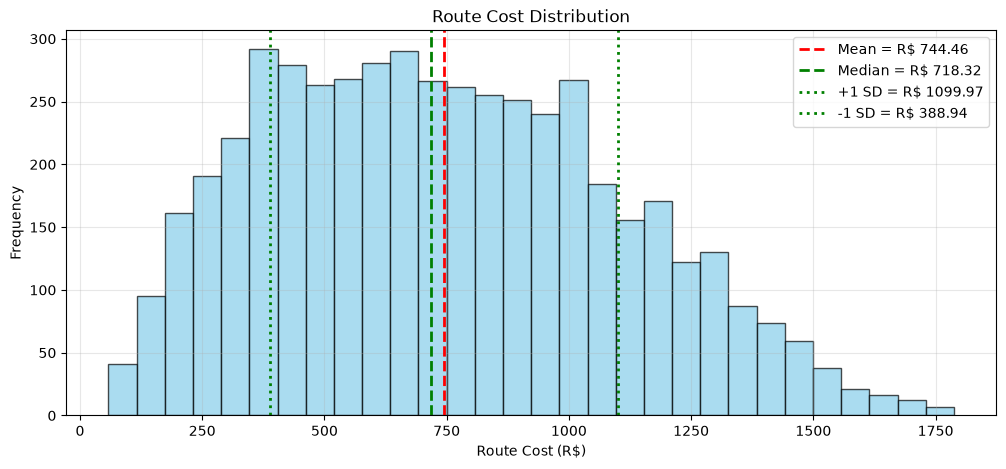

In [24]:
# Route cost distribution
plt.figure(figsize=(12, 5))

plt.hist(
    route_cost_col,
    bins=30,
    color="skyblue",
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    mean_route_cost,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Mean = R$ {mean_route_cost:.2f}"
)

plt.axvline(
    median_route_cost,
    color="green",
    linestyle="--",
    linewidth=2,
    label=f"Median = R$ {median_route_cost:.2f}"
)

plt.axvline(
    mean_route_cost + std_route_cost,
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"+1 SD = R$ {mean_route_cost + std_route_cost:.2f}"
)

plt.axvline(
    mean_route_cost - std_route_cost,
    color="green",
    linestyle=":",
    linewidth=2,
    label=f"-1 SD = R$ {mean_route_cost - std_route_cost:.2f}"
)

plt.title("Route Cost Distribution")
plt.xlabel("Route Cost (R$)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [25]:
# Boolean filter for high-cost routes
high_cost_threshold = mean_route_cost + std_route_cost

high_cost_route = logistics_data[
    logistics_data[:, 3] > high_cost_threshold
]

print(f"\n--- ANALYSIS: HIGH-COST ROUTES "
      f"(Route Cost > R$ {high_cost_threshold:.2f}) ---\n")

print(f"Number of high-cost routes: {high_cost_route.shape[0]}")

# Segment statistics
mean_distance_high_cost = np.mean(high_cost_route[:, 0])
mean_delivery_time_high_cost = np.mean(high_cost_route[:, 1])
mean_stop_high_cost = np.mean(high_cost_route[:, 2])
mean_route_cost_high_cost = np.mean(high_cost_route[:, 3])

print(f"Average Distance: {mean_distance_high_cost:.2f} km")
print(f"Average Delivery Time: {mean_delivery_time_high_cost:.2f} min")
print(f"Average Number of Stops: {mean_stop_high_cost:.2f}")
print(f"Average Route Cost: {mean_route_cost_high_cost:.2f}")


--- ANALYSIS: HIGH-COST ROUTES (Route Cost > R$ 1099.97) ---

Number of high-cost routes: 880
Average Distance: 258.47 km
Average Delivery Time: 318.33 min
Average Number of Stops: 9.48
Average Route Cost: 1297.21


In [26]:
# Filter for operationally efficient routes
efficient_routes = logistics_data[
    (logistics_data[:, 0] > mean_distance) &
    (logistics_data[:, 3] < mean_route_cost)
]

print("\n--- ANALYSIS: OPERATIONALLY EFFICIENT ROUTES ---\n")
print(f"Number of operationally efficient routes: {efficient_routes.shape[0]}")

# Segment statistics
mean_distance_efficient = np.mean(efficient_routes[:, 0])
mean_delivery_time_efficient = np.mean(efficient_routes[:, 1])
mean_stops_efficient = np.mean(efficient_routes[:, 2])
mean_route_cost_efficient = np.mean(efficient_routes[:, 3])

print(f"Average Distance: {mean_distance_efficient:.2f} km")
print(f"Average Delivery Time: {mean_delivery_time_efficient:.2f} min")
print(f"Average Number of Stops: {mean_stops_efficient:.2f}")
print(f"Average Route Cost: R$ {mean_route_cost_efficient:.2f}")


--- ANALYSIS: OPERATIONALLY EFFICIENT ROUTES ---

Number of operationally efficient routes: 338
Average Distance: 185.75 km
Average Delivery Time: 247.16 min
Average Number of Stops: 4.96
Average Route Cost: R$ 646.59


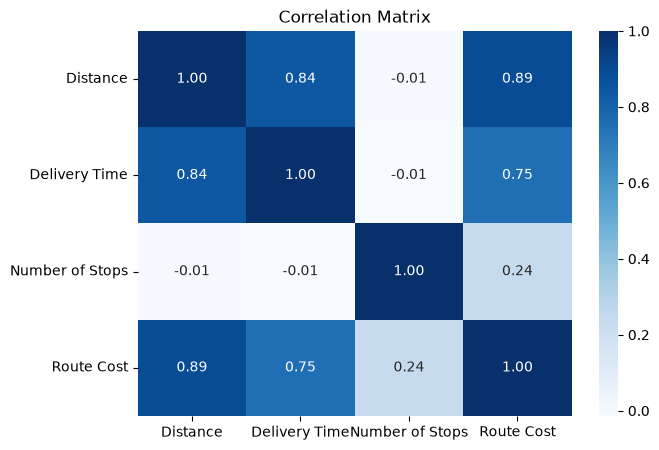

In [27]:
# Calculate correlation matrix
correlation_matrix = np.corrcoef(logistics_data, rowvar=False)

# Define variable names
variable_names = [
    "Distance",
    "Delivery Time",
    "Number of Stops",
    "Route Cost"
]

# Convert correlation matrix to DataFrame
correlation_df = pd.DataFrame(
    correlation_matrix,
    index=variable_names,
    columns=variable_names
)

# Correlation matrix heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_df,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Correlation Matrix")

plt.savefig(r"C:\Users\Guilherme\projects_python\logistics_operations_statistical_analysis\images\correlation_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

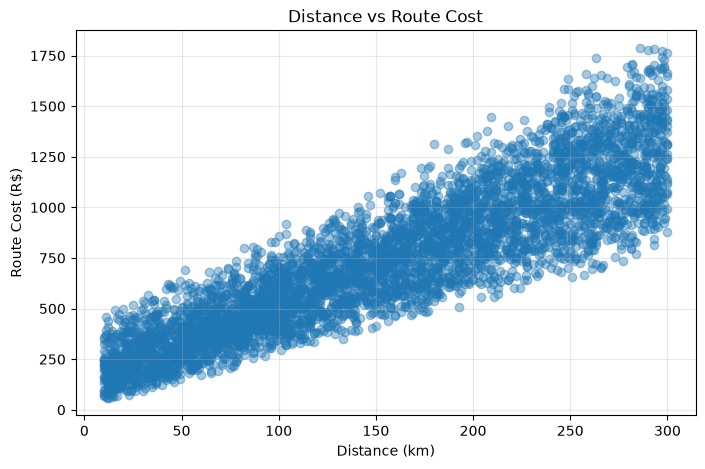

In [28]:
# Distance vs Route Cost
plt.figure(figsize=(8, 5))

plt.scatter(
    distance_col,
    route_cost_col,
    alpha=0.4
)

plt.title("Distance vs Route Cost")
plt.xlabel("Distance (km)")
plt.ylabel("Route Cost (R$)")
plt.grid(alpha=0.3)

plt.savefig(r"C:\Users\Guilherme\projects_python\logistics_operations_statistical_analysis\images\distance_vs_route_cost.png", dpi=300, bbox_inches="tight")
plt.show()

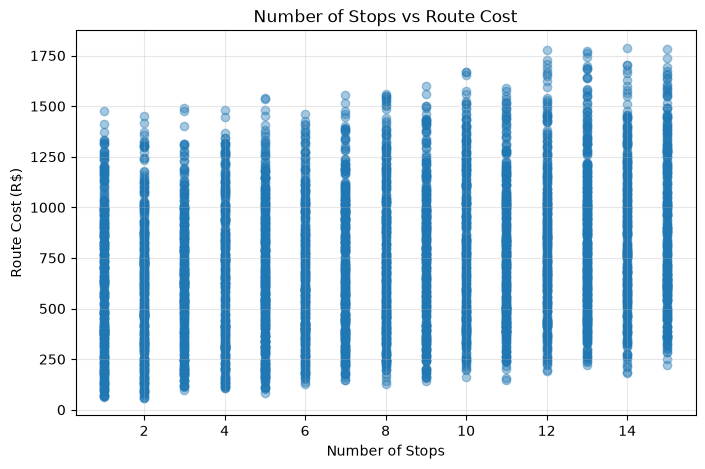

In [29]:
# Number of Stops vs Route Cost
plt.figure(figsize=(8, 5))

plt.scatter(
    stops_col,
    route_cost_col,
    alpha=0.4
)

plt.title("Number of Stops vs Route Cost")
plt.xlabel("Number of Stops")
plt.ylabel("Route Cost (R$)")
plt.grid(alpha=0.3)

plt.savefig(r"C:\Users\Guilherme\projects_python\logistics_operations_statistical_analysis\images\route_cost_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [30]:
# Route cost percentiles
route_cost_percentiles = np.percentile(
    route_cost_col,
    [25, 50, 75, 90, 95]
)

print("\n--- ROUTE COST PERCENTILES ---\n")

print(f"25th Percentile: R$ {route_cost_percentiles[0]:.2f}")
print(f"50th Percentile: R$ {route_cost_percentiles[1]:.2f}")
print(f"75th Percentile: R$ {route_cost_percentiles[2]:.2f}")
print(f"90th Percentile: R$ {route_cost_percentiles[3]:.2f}")
print(f"95th Percentile: R$ {route_cost_percentiles[4]:.2f}")


--- ROUTE COST PERCENTILES ---

25th Percentile: R$ 455.87
50th Percentile: R$ 718.32
75th Percentile: R$ 999.10
90th Percentile: R$ 1239.25
95th Percentile: R$ 1368.95
